# Lab 04 : Réseaux convolutifs (CNN) – détecter le cancer du sein sur des échographies

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/atouammi/Formation_CNN_API_Docker_Module4/blob/main/Labs/04_breast_cancer_cnn.ipynb)

Dans le lab 03, nos réseaux de neurones recevaient des images « aplaties » en une simple liste de pixels. Ici, nous passons aux **réseaux de neurones convolutifs (CNN)**, l'architecture de référence en vision par ordinateur, et nous les appliquons à un problème réel : **distinguer les tumeurs malignes des tumeurs bénignes sur des échographies mammaires**.

> ⚠️ **Avertissement** : ce notebook est un exercice pédagogique. Les modèles entraînés ici ne sont **pas** des dispositifs médicaux et ne doivent jamais servir à poser un diagnostic.

*Ce lab s'inspire du notebook Kaggle [Detecting Breast Cancer with Computer Vision](https://www.kaggle.com/code/timothyabwao/detecting-breast-cancer-with-computer-vision) de Timothy Abwao, adapté à un jeu de données plus léger et librement téléchargeable.*

## Objectifs pédagogiques

À la fin de ce lab, vous saurez :

- Expliquer ce que font les couches de **convolution** et de **pooling** d'un CNN.
- Expliquer pourquoi l'**accuracy** est trompeuse quand les classes sont déséquilibrées, et utiliser le **ROC-AUC**, la **sensibilité** et la **spécificité** à la place.
- Utiliser l'**augmentation de données** pour rendre un modèle plus robuste.
- Construire et entraîner un **CNN** avec Keras.
- Utiliser le **transfert d'apprentissage** (transfer learning) à partir d'un modèle pré-entraîné (MobileNetV3).
- Choisir un **seuil de décision** adapté à un contexte médical.
- Enregistrer un modèle pour le réutiliser (par exemple dans une API).

In [1]:
# ⚙️ Configuration – exécutez cette cellule en premier.
# - Sur Google Colab : récupère les fichiers du cours (plotting_utils/, assets/, requirements.txt)
#   et installe ce qui manque.
# - En local (VS Code) : rien à faire, l'environnement est déjà installé avec requirements.txt.
import os, sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    REPO_DIR = "/content/Formation_CNN_API_Docker_Module4"
    if not os.path.exists(REPO_DIR):
        !git clone -q https://github.com/atouammi/Formation_CNN_API_Docker_Module4.git {REPO_DIR}
    %cd {REPO_DIR}/Labs

if "." not in sys.path:
    sys.path.append(".")
print("Environnement :", "Google Colab" if IN_COLAB else "local")

Environnement : local


In [2]:
# Note pédagogique : cette cellule importe les bibliothèques du lab et fixe la graine aléatoire pour des résultats plus reproductibles.

import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn import metrics
from tensorflow.keras import layers

SEED = 42
tf.keras.utils.set_random_seed(SEED)

plt.rc("axes.spines", right=False, top=False)

## Partie 1 : Le contexte

Le cancer du sein est le **cancer le plus fréquent dans le monde** : en 2020, il représentait environ **2,26 millions** de nouveaux cas sur 19,3 millions, soit 11,7 % (source : [Global Cancer Observatory – GLOBOCAN 2020](https://gco.iarc.fr/today/data/factsheets/cancers/39-All-cancers-fact-sheet.pdf)).

Un dépistage précoce augmente fortement les chances de guérison. L'**échographie** est un examen peu coûteux et non irradiant, très utilisé pour examiner une masse mammaire. Mais l'interprétation des images demande un radiologue expérimenté, et les spécialistes manquent dans de nombreuses régions. L'IA peut aider à **prioriser** les examens ou à fournir un **deuxième avis**, à condition d'être évaluée avec rigueur.

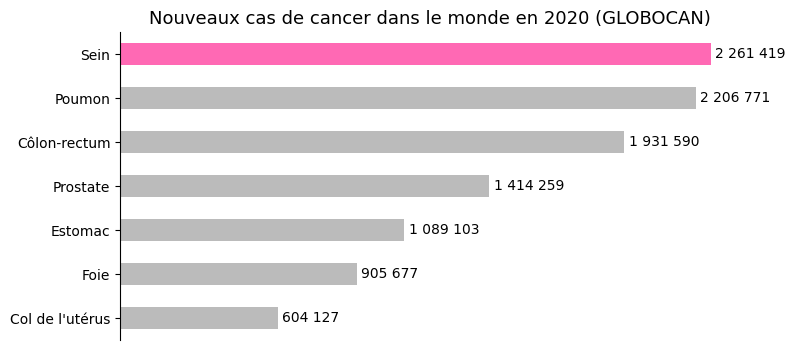

In [3]:
# Note pédagogique : ce graphique situe le cancer du sein parmi les cancers les plus fréquents (GLOBOCAN 2020).

cancer_data = pd.Series({
    "Sein": 2261419,
    "Poumon": 2206771,
    "Côlon-rectum": 1931590,
    "Prostate": 1414259,
    "Estomac": 1089103,
    "Foie": 905677,
    "Col de l'utérus": 604127,
}).sort_values()

ax = cancer_data.plot.barh(figsize=(8, 4), color=["#bbb"] * 6 + ["hotpink"])
ax.bar_label(ax.containers[0], [f"{x:,}".replace(",", " ") for x in cancer_data], padding=3)
ax.set_title("Nouveaux cas de cancer dans le monde en 2020 (GLOBOCAN)", size=13)
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
plt.show()

## Partie 2 : Les données – BreastMNIST

Nous utilisons **BreastMNIST**, issu de la collection [MedMNIST](https://medmnist.com/) :

- **780 échographies mammaires** en niveaux de gris, redimensionnées ici en **128 × 128 pixels**.
- Images d'origine : *Breast Ultrasound Images Dataset* (BUSI), collecté auprès de 600 patientes – Al-Dhabyani W. *et al.*, *Data in Brief*, 28:104863, 2020.
- Deux classes : **maligne** (cancer) ou **normale / bénigne**.
- Un découpage déjà prêt : entraînement (70 %), validation (10 %) et test (20 %).
- Licence **CC BY 4.0** – Yang J. *et al.*, *MedMNIST v2*, *Scientific Data*, 10:41, 2023.

Le fichier fait environ 11 Mo et se télécharge sans compte.

In [4]:
# Note pédagogique : on télécharge le jeu de données une seule fois, puis on le réutilise depuis le dossier data/.

DATA_URL = "https://zenodo.org/records/10519652/files/breastmnist_128.npz"
DATA_PATH = Path("data") / "breastmnist_128.npz"
DATA_PATH.parent.mkdir(exist_ok=True)

if not DATA_PATH.exists():
    print("Téléchargement de BreastMNIST (environ 11 Mo)…")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

data = np.load(DATA_PATH)
print("Fichier :", DATA_PATH)
print("Contenu :", data.files)

Fichier : data/breastmnist_128.npz
Contenu : ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']


Dans le fichier d'origine, l'étiquette **0 signifie « maligne »** et **1 signifie « normale ou bénigne »**. Nous inversons ces étiquettes pour que la classe qui nous intéresse, **le cancer, soit la classe positive (1)**. C'est la convention habituelle : « positif » veut dire « la maladie est détectée ».

In [5]:
# Note pédagogique : on prépare les images (ajout d'un canal) et on inverse les étiquettes pour que maligne = 1.

CLASS_NAMES = ["bénigne/normale", "maligne"]


def load_split(split):
    images = data[f"{split}_images"][..., np.newaxis].astype("float32")  # (n, 128, 128, 1)
    labels = 1 - data[f"{split}_labels"].reshape(-1)                      # maligne = 1
    return images, labels


X_train, y_train = load_split("train")
X_val, y_val = load_split("val")
X_test, y_test = load_split("test")

for name, X, y in [("Entraînement", X_train, y_train), ("Validation", X_val, y_val), ("Test", X_test, y_test)]:
    print(f"{name:13s}: {len(X):3d} images, dont {y.sum():3d} malignes ({y.mean():.0%})")
print("Taille d'une image :", X_train.shape[1:])

Entraînement : 546 images, dont 147 malignes (27%)
Validation   :  78 images, dont  21 malignes (27%)
Test         : 156 images, dont  42 malignes (27%)
Taille d'une image : (128, 128, 1)


### 🔍 À quoi ressemblent les images ?

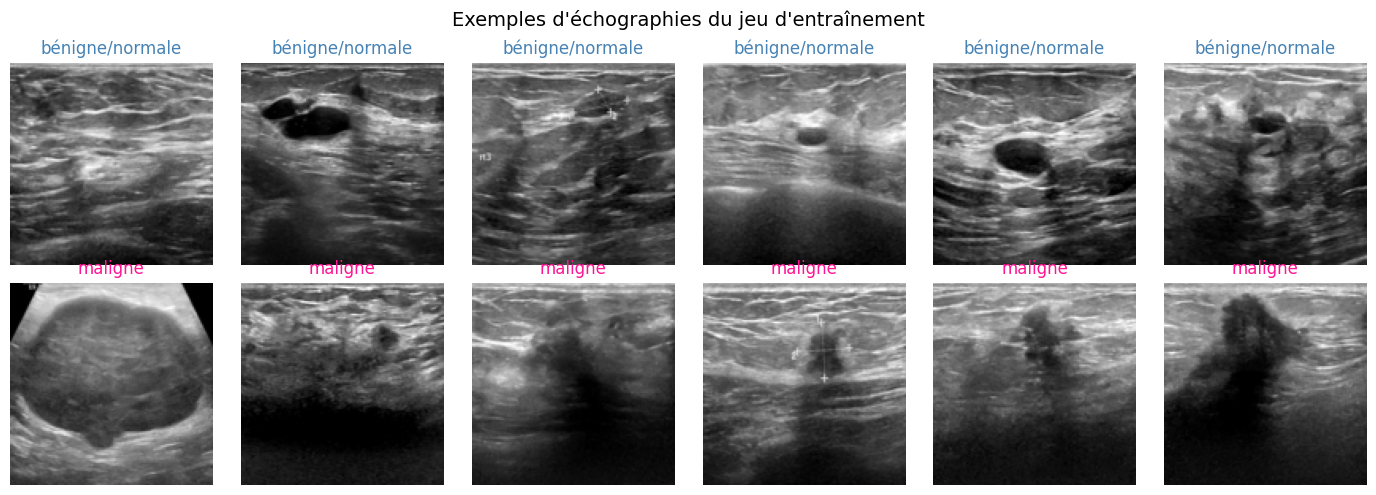

In [6]:
# Note pédagogique : afficher des exemples aide à comprendre la difficulté de la tâche, même pour un œil humain.

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for row, label in enumerate([0, 1]):
    indices = np.where(y_train == label)[0][:6]
    for ax, idx in zip(axes[row], indices):
        ax.imshow(X_train[idx, ..., 0], cmap="gray")
        ax.set_title(CLASS_NAMES[label], color="steelblue" if label == 0 else "deeppink")
        ax.axis("off")
fig.suptitle("Exemples d'échographies du jeu d'entraînement", size=14)
plt.tight_layout()
plt.show()

🤔 **Question** : arrivez-vous à distinguer les tumeurs malignes des autres ? Les tumeurs malignes ont souvent des contours plus irréguliers, mais la différence est loin d'être évidente. C'est exactement le genre de motifs visuels subtils qu'un CNN peut apprendre.

## Partie 3 : Pourquoi l'accuracy est trompeuse

Regardons la répartition des classes :

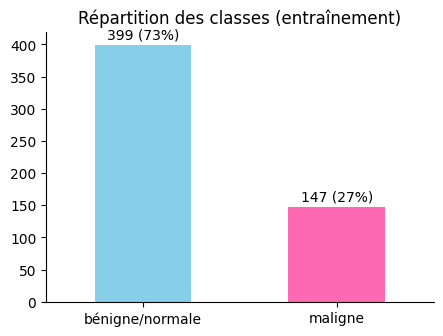

In [7]:
# Note pédagogique : le graphique met en évidence le déséquilibre entre les deux classes.

counts = pd.Series(y_train).value_counts().sort_index()
ax = counts.plot.bar(color=["skyblue", "hotpink"], figsize=(5, 3.5))
ax.set_xticklabels(CLASS_NAMES, rotation=0)
ax.bar_label(ax.containers[0], [f"{n} ({n / len(y_train):.0%})" for n in counts], padding=2)
ax.set_title("Répartition des classes (entraînement)")
plt.show()

Seules **27 % des images** sont malignes. Les classes sont **déséquilibrées**.

Imaginons un « modèle » paresseux qui répond **toujours « bénigne »**, sans même regarder l'image. Quelle serait son accuracy ?

In [8]:
# Note pédagogique : un prédicteur qui répond toujours « bénigne » montre pourquoi l'accuracy seule ne suffit pas.

always_benign = np.zeros_like(y_test)

print(f"Accuracy : {metrics.accuracy_score(y_test, always_benign):.0%}")
print(f"ROC-AUC  : {metrics.roc_auc_score(y_test, always_benign):.2f}")
print(f"Cancers détectés : {((always_benign == 1) & (y_test == 1)).sum()} sur {y_test.sum()}")

Accuracy : 73%
ROC-AUC  : 0.50
Cancers détectés : 0 sur 42


Ce « modèle » obtient environ **73 % d'accuracy**… tout en **ne détectant aucun cancer** ! L'accuracy récompense le fait de prédire la classe majoritaire.

Nous utiliserons donc d'autres mesures :

| Mesure | Question à laquelle elle répond |
|--------|---------------------------------|
| **Sensibilité** (rappel, *recall*) | Parmi les cancers, quelle proportion le modèle détecte-t-il ? |
| **Spécificité** | Parmi les cas bénins, quelle proportion le modèle reconnaît-il comme bénins ? |
| **ROC-AUC** | Le modèle attribue-t-il un score plus élevé aux cas malins qu'aux cas bénins ? 0,5 = hasard, 1 = parfait. Cette mesure ne dépend pas du seuil de décision. |

Et la **matrice de confusion**, qui compte les quatre situations possibles :

|  | Prédit bénigne | Prédit maligne |
|--|----------------|----------------|
| **Réellement bénigne** | ✅ Vrai négatif | ⚠️ **Faux positif** : fausse alarme, examens inutiles et anxiété |
| **Réellement maligne** | ❌ **Faux négatif** : cancer manqué, retard de traitement | ✅ Vrai positif |

En dépistage, un **faux négatif** est en général bien plus grave qu'un faux positif.

## Partie 4 : L'augmentation de données

Avec seulement 546 images d'entraînement, un réseau risque d'**apprendre par cœur** les exemples (surapprentissage). L'**augmentation de données** crée, à chaque époque, des versions légèrement modifiées des images :

- **Retournement horizontal** : une tumeur reste une tumeur, vue dans un miroir.
- **Rotation légère** : la sonde n'est jamais tenue exactement au même angle.
- **Variation de contraste** : les réglages de l'échographe varient d'un appareil à l'autre.

Le modèle apprend ainsi que ces variations ne changent pas le diagnostic.

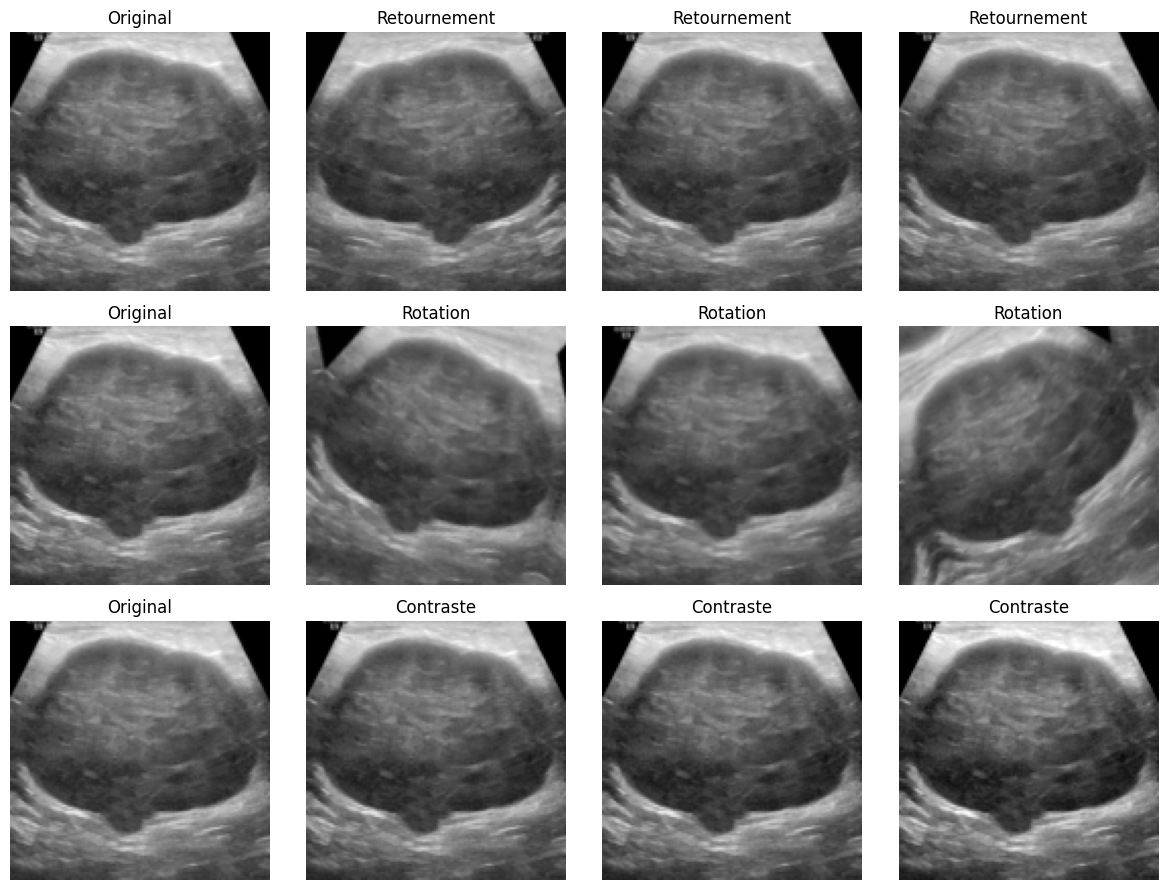

In [9]:
# Note pédagogique : on applique chaque transformation plusieurs fois à la même image pour visualiser son effet.

augmentations = {
    "Retournement": layers.RandomFlip("horizontal", seed=SEED),
    "Rotation": layers.RandomRotation(0.1, seed=SEED),
    "Contraste": layers.RandomContrast(0.3, seed=SEED),
}
sample = X_train[np.where(y_train == 1)[0][0]]

fig, axes = plt.subplots(len(augmentations), 4, figsize=(12, 9))
for row, (name, layer) in enumerate(augmentations.items()):
    axes[row, 0].imshow(sample[..., 0], cmap="gray")
    axes[row, 0].set_title("Original")
    for ax in axes[row, 1:]:
        augmented = layer(sample, training=True).numpy()
        ax.imshow(augmented[..., 0], cmap="gray", vmin=0, vmax=255)
        ax.set_title(name)
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.show()

## Partie 5 : Des fonctions utilitaires

Pour comparer équitablement nos modèles, nous les entraînons et les évaluons tous de la même façon.

- **Pondération des classes** (`class_weight`) : chaque erreur sur un cas malin (minoritaire) « coûte » plus cher pendant l'entraînement. Le modèle ne peut plus se contenter de prédire la classe majoritaire.
- **Arrêt précoce** (`EarlyStopping`) : on arrête l'entraînement quand le ROC-AUC de validation ne progresse plus, et on garde les meilleurs poids.

In [10]:
# Note pédagogique : ces fonctions entraînent et évaluent chaque modèle de la même façon, pour une comparaison équitable.

n_benign, n_malignant = np.bincount(y_train)
CLASS_WEIGHT = {0: len(y_train) / (2 * n_benign), 1: len(y_train) / (2 * n_malignant)}
print(f"Poids des classes : bénigne = {CLASS_WEIGHT[0]:.2f}, maligne = {CLASS_WEIGHT[1]:.2f}")


def train_model(model, X_tr, X_va, epochs=40, learning_rate=1e-3):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(name="roc_auc"), "binary_accuracy"],
    )
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_roc_auc", mode="max", patience=8, restore_best_weights=True
    )
    history = model.fit(
        X_tr, y_train, validation_data=(X_va, y_val), epochs=epochs, batch_size=32,
        class_weight=CLASS_WEIGHT, callbacks=[early_stopping], verbose=0,
    )
    hist = pd.DataFrame(history.history)
    print(f"Entraînement terminé après {len(hist)} époques.")

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    hist[["roc_auc", "val_roc_auc"]].plot(ax=axes[0], title="ROC-AUC")
    hist[["loss", "val_loss"]].plot(ax=axes[1], title="Perte (loss)")
    for ax in axes:
        ax.set_xlabel("Époque")
        ax.legend(["Entraînement", "Validation"])
    plt.show()
    return history


def evaluate_model(model, X, y, threshold=0.5, name=None):
    scores = model.predict(X, verbose=0).reshape(-1)
    preds = (scores >= threshold).astype(int)
    tn, fp, fn, tp = metrics.confusion_matrix(y, preds).ravel()
    results = {
        "ROC-AUC": metrics.roc_auc_score(y, scores),
        "Accuracy": metrics.accuracy_score(y, preds),
        "Sensibilité": tp / (tp + fn),
        "Spécificité": tn / (tn + fp),
        "Cancers manqués (FN)": fn,
        "Fausses alarmes (FP)": fp,
    }
    print(f"{'ROC-AUC':22s}: {results['ROC-AUC']:.3f}")
    for key in ["Accuracy", "Sensibilité", "Spécificité"]:
        print(f"{key:22s}: {results[key]:.1%}")
    for key in ["Cancers manqués (FN)", "Fausses alarmes (FP)"]:
        print(f"{key:22s}: {results[key]}")

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    metrics.RocCurveDisplay.from_predictions(y, scores, ax=axes[0], name=name or model.name)
    axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
    axes[0].set_title("Courbe ROC")
    metrics.ConfusionMatrixDisplay.from_predictions(
        y, preds, display_labels=CLASS_NAMES, ax=axes[1], colorbar=False, cmap="RdPu"
    )
    axes[1].set_title(f"Matrice de confusion (seuil = {threshold:.2f})")
    axes[1].set_xlabel("Prédiction")
    axes[1].set_ylabel("Réalité")
    plt.tight_layout()
    plt.show()
    return results, scores

Poids des classes : bénigne = 0.68, maligne = 1.86


## Partie 6 : Notre premier CNN

### 🧠 Comment fonctionne un CNN ?

Dans le lab 03, chaque neurone de la première couche était relié à **tous** les pixels. Pour une image de 128 × 128, cela fait 16 384 poids par neurone, et l'information « ces pixels sont voisins » est perdue.

Un CNN procède autrement :

| Couche | Rôle |
|--------|------|
| **Convolution** (`Conv2D`) | De petits filtres (ici 3 × 3) glissent sur l'image et réagissent à des motifs locaux : bords, textures, puis formes plus complexes dans les couches profondes. Le même filtre est réutilisé partout dans l'image : très peu de poids à apprendre. |
| **Pooling** (`MaxPooling2D`) | Réduit la taille de l'image en gardant la valeur la plus forte de chaque zone 2 × 2. Le réseau devient moins sensible à la position exacte d'un motif. |
| **Global Average Pooling** | Résume chaque carte de caractéristiques en un seul nombre avant la classification. |
| **Dropout** | Désactive au hasard une partie des neurones pendant l'entraînement pour limiter le surapprentissage. |

On empile plusieurs blocs « convolution + pooling » : chaque bloc détecte des motifs de plus en plus abstraits.

In [11]:
# Note pédagogique : ce CNN empile trois blocs convolution + pooling, précédés des couches d'augmentation de données.

cnn_model = tf.keras.Sequential([
    layers.Input(shape=(128, 128, 1)),
    # Augmentation de données (active uniquement pendant l'entraînement)
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.1, seed=SEED),
    layers.RandomContrast(0.2, seed=SEED),
    # Mise à l'échelle des pixels de [0, 255] vers [0, 1]
    layers.Rescaling(1.0 / 255),
    # Bloc convolutif 1 : motifs simples (bords, textures)
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    # Bloc convolutif 2 : combinaisons de motifs
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    # Bloc convolutif 3 : motifs plus abstraits (formes, contours de la lésion)
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),
    # Classification
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid"),  # probabilité que la tumeur soit maligne
], name="CNN_maison")

cnn_model.summary()

Model: "CNN_maison"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 128, 128, 1)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_1               │ (None, 128, 128, 1)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,993 (394.50 KB)

 Trainable params: 100,993 (394.50 KB)

 Non-trainable params: 0 (0.00 B)

Regardez le nombre de paramètres : environ **100 000**, alors qu'un réseau dense relié directement aux 16 384 pixels en aurait déjà plus d'un million dès sa première couche de 64 neurones.

Entraînons-le (environ une minute sur CPU) :

Entraînement terminé après 31 époques.


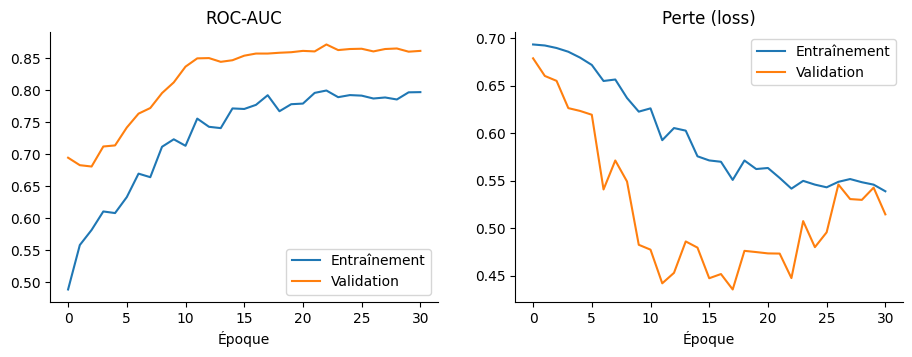

In [12]:
# Note pédagogique : l'entraînement utilise la pondération des classes et l'arrêt précoce définis plus haut.

cnn_history = train_model(cnn_model, X_train, X_val)

ROC-AUC               : 0.812
Accuracy              : 80.8%
Sensibilité           : 47.6%
Spécificité           : 93.0%
Cancers manqués (FN)  : 22
Fausses alarmes (FP)  : 8


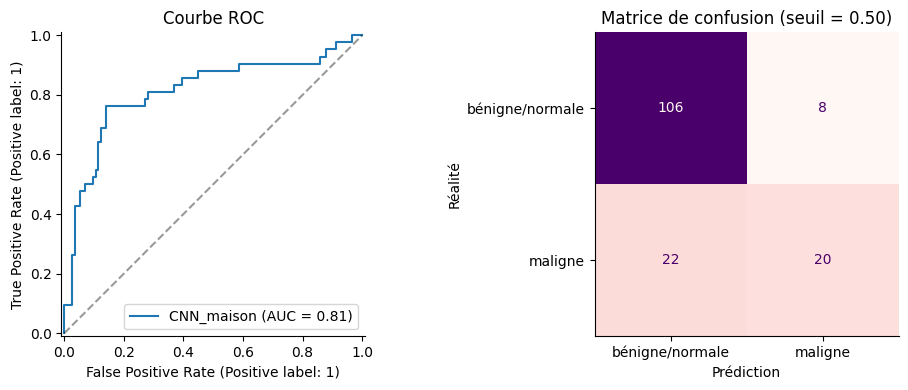

In [13]:
# Note pédagogique : on évalue le CNN sur le jeu de test, jamais vu pendant l'entraînement.

cnn_results, cnn_scores = evaluate_model(cnn_model, X_test, y_test)

💬 **À observer** : regardez l'accuracy, puis la **sensibilité** et le nombre de **cancers manqués**. Une accuracy correcte peut cacher une sensibilité faible.

## Partie 7 : Le transfert d'apprentissage

Entraîner un CNN performant demande en général des **dizaines de milliers d'images**. Nous n'en avons que 546.

Le **transfert d'apprentissage** (transfer learning) consiste à réutiliser un réseau déjà entraîné sur un immense jeu de données, ici **ImageNet** (1,2 million de photos de 1 000 catégories). Ses premières couches ont appris à détecter des bords, des textures et des formes : ces connaissances restent utiles pour nos échographies.

Nous utilisons **MobileNetV3Small**, un modèle léger conçu pour les téléphones, qui s'entraîne vite même sur CPU :

1. On charge MobileNetV3 **sans** sa couche de classification d'origine (`include_top=False`).
2. On **gèle** ses poids (`trainable = False`) : ils ne seront pas modifiés.
3. On ajoute par-dessus notre petite tête de classification, la seule partie entraînée.

MobileNetV3 attend des images **en couleur** (3 canaux). Nos échographies sont en niveaux de gris : nous recopions simplement le canal gris trois fois.

In [14]:
# Note pédagogique : on recopie le canal gris trois fois pour obtenir des images au format attendu par MobileNetV3.

X_train_rgb, X_val_rgb, X_test_rgb = (np.repeat(X, 3, axis=-1) for X in (X_train, X_val, X_test))
print("Nouvelle forme des images :", X_train_rgb.shape[1:])

Nouvelle forme des images : (128, 128, 3)


In [15]:
# Note pédagogique : MobileNetV3 pré-entraîné sur ImageNet sert d'extracteur de caractéristiques gelé ; seule la tête est entraînée.
# Le premier lancement télécharge les poids pré-entraînés (environ 4 Mo).

base_model = tf.keras.applications.MobileNetV3Small(
    input_shape=(128, 128, 3),
    include_top=False,       # sans la couche de classification d'ImageNet
    weights="imagenet",      # poids pré-entraînés
    pooling="avg",
)
base_model.trainable = False  # on gèle le réseau pré-entraîné

mobilenet_model = tf.keras.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.1, seed=SEED),
    layers.RandomContrast(0.2, seed=SEED),
    base_model,  # MobileNetV3 intègre sa propre mise à l'échelle des pixels
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid"),
], name="MobileNetV3")

mobilenet_model.summary()

Model: "MobileNetV3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_2 (RandomFlip)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_2               │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_2               │ (None, 128, 128, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Small (Functional)   │ (None, 576)            │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 976,113 (3.72 MB)

 Trainable params: 36,993 (144.50 KB)

 Non-trainable params: 939,120 (3.58 MB)

Le modèle compte environ un million de paramètres, mais **seuls quelques dizaines de milliers sont entraînables** : ceux de notre tête de classification.

Entraînement terminé après 14 époques.


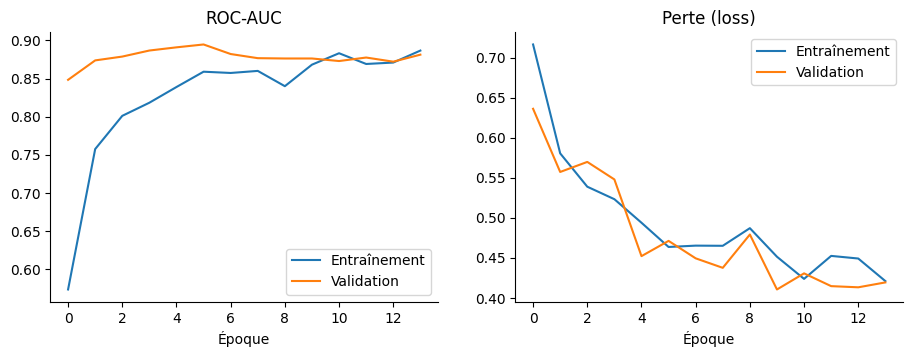

In [16]:
# Note pédagogique : seule la tête de classification est entraînée, ce qui est rapide même sur CPU.

mobilenet_history = train_model(mobilenet_model, X_train_rgb, X_val_rgb, epochs=30)

ROC-AUC               : 0.851
Accuracy              : 71.8%
Sensibilité           : 81.0%
Spécificité           : 68.4%
Cancers manqués (FN)  : 8
Fausses alarmes (FP)  : 36


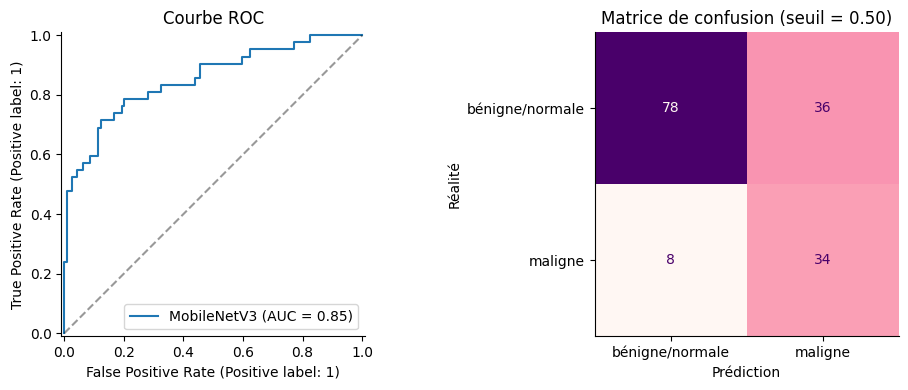

In [17]:
# Note pédagogique : on évalue le modèle à transfert d'apprentissage sur le même jeu de test.

mobilenet_results, mobilenet_scores = evaluate_model(mobilenet_model, X_test_rgb, y_test)

## Partie 8 : Comparer les modèles

In [18]:
# Note pédagogique : le tableau compare les deux modèles sur les mêmes mesures et le même jeu de test.

comparison = pd.DataFrame({"CNN maison": cnn_results, "MobileNetV3": mobilenet_results}).T
comparison.style.format({
    "ROC-AUC": "{:.3f}", "Accuracy": "{:.1%}", "Sensibilité": "{:.1%}", "Spécificité": "{:.1%}",
    "Cancers manqués (FN)": "{:.0f}", "Fausses alarmes (FP)": "{:.0f}",
})

,ROC-AUC,Accuracy,Sensibilité,Spécificité,Cancers manqués (FN),Fausses alarmes (FP)
CNN maison,0.812,80.8%,47.6%,93.0%,22,8
MobileNetV3,0.851,71.8%,81.0%,68.4%,8,36


💬 **Questions pour la discussion**

- Quel modèle a la meilleure **accuracy** ? Est-ce aussi celui qui manque le moins de cancers ?
- Quel modèle a le meilleur **ROC-AUC** ?
- Si vous deviez choisir un modèle pour **aider au dépistage**, lequel prendriez-vous, et pourquoi ?

Les résultats peuvent varier un peu d'une exécution à l'autre, mais on observe souvent ceci : un modèle peut avoir une meilleure accuracy tout en **manquant beaucoup plus de cancers**. Avec seulement 156 images de test, dont 42 malignes, chaque erreur pèse lourd : quelques images de plus ou de moins changent les pourcentages de plusieurs points.

## Partie 9 : Choisir le seuil de décision

Un modèle ne répond pas « maligne » ou « bénigne » : il donne un **score entre 0 et 1**. C'est nous qui choisissons le **seuil** au-delà duquel on considère le cas comme malin. Par défaut, ce seuil vaut 0,5, mais rien n'oblige à garder cette valeur :

- **Seuil bas** → on détecte plus de cancers (sensibilité ↑), mais avec plus de fausses alarmes (spécificité ↓).
- **Seuil haut** → moins de fausses alarmes, mais plus de cancers manqués.

Le bon compromis est une **décision médicale**, pas seulement technique. En dépistage, on vise souvent une sensibilité élevée.

⚠️ **Bonne pratique** : on choisit le seuil sur le jeu de **validation**, jamais sur le jeu de test. Sinon, on « triche » en ajustant le modèle aux données qui servent à l'évaluer.

ROC-AUC sur la validation : {'CNN maison': 0.87, 'MobileNetV3': 0.895}
Modèle retenu : MobileNetV3
Seuil choisi pour une sensibilité ≥ 90% : 0.51


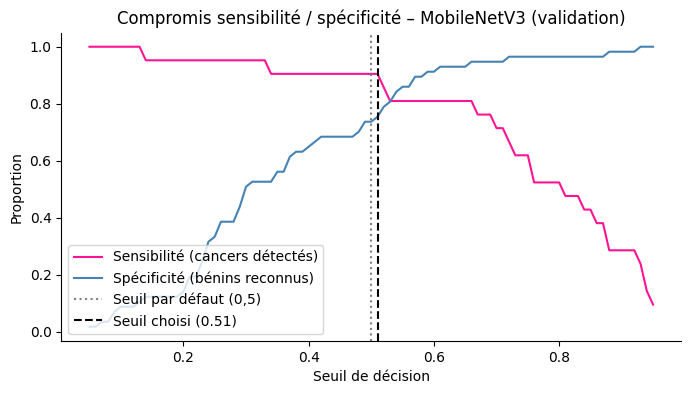

In [19]:
# Note pédagogique : on calcule sensibilité et spécificité pour chaque seuil possible, sur le jeu de validation.

# On choisit le modèle qui a le meilleur ROC-AUC sur la VALIDATION (pas sur le test)
candidates = {"CNN maison": (cnn_model, X_val), "MobileNetV3": (mobilenet_model, X_val_rgb)}
val_auc = {name: float(metrics.roc_auc_score(y_val, m.predict(X, verbose=0).reshape(-1)))
           for name, (m, X) in candidates.items()}
best_name = max(val_auc, key=val_auc.get)
best_model, X_val_best = candidates[best_name]
print("ROC-AUC sur la validation :", {k: round(v, 3) for k, v in val_auc.items()})
print("Modèle retenu :", best_name)

val_scores = best_model.predict(X_val_best, verbose=0).reshape(-1)
thresholds = np.linspace(0.05, 0.95, 91)
sensitivity = [((val_scores >= t) & (y_val == 1)).sum() / (y_val == 1).sum() for t in thresholds]
specificity = [((val_scores < t) & (y_val == 0)).sum() / (y_val == 0).sum() for t in thresholds]

# Seuil le plus élevé qui garde une sensibilité d'au moins 90 % sur la validation
TARGET_SENSITIVITY = 0.90
chosen_threshold = max(t for t, s in zip(thresholds, sensitivity) if s >= TARGET_SENSITIVITY)
print(f"Seuil choisi pour une sensibilité ≥ {TARGET_SENSITIVITY:.0%} : {chosen_threshold:.2f}")

plt.figure(figsize=(8, 4))
plt.plot(thresholds, sensitivity, label="Sensibilité (cancers détectés)", color="deeppink")
plt.plot(thresholds, specificity, label="Spécificité (bénins reconnus)", color="steelblue")
plt.axvline(0.5, color="gray", linestyle=":", label="Seuil par défaut (0,5)")
plt.axvline(chosen_threshold, color="black", linestyle="--", label=f"Seuil choisi ({chosen_threshold:.2f})")
plt.xlabel("Seuil de décision")
plt.ylabel("Proportion")
plt.title(f"Compromis sensibilité / spécificité – {best_name} (validation)")
plt.legend(loc="lower left")
plt.show()

Appliquons maintenant ce seuil au **jeu de test** :

ROC-AUC               : 0.851
Accuracy              : 73.1%
Sensibilité           : 81.0%
Spécificité           : 70.2%
Cancers manqués (FN)  : 8
Fausses alarmes (FP)  : 34


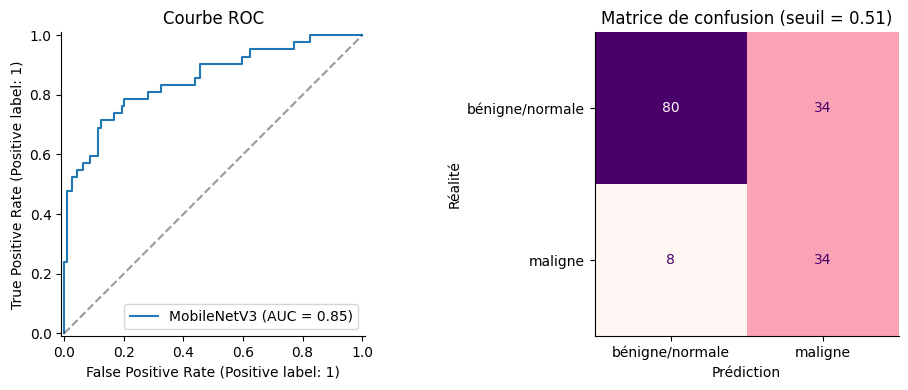

In [20]:
# Note pédagogique : on vérifie sur le jeu de test l'effet du seuil choisi sur la validation.

X_test_best = X_test_rgb if best_name == "MobileNetV3" else X_test
_ = evaluate_model(best_model, X_test_best, y_test, threshold=chosen_threshold, name=best_name)

Pour bien voir le compromis, comparons quelques seuils sur le jeu de test :

In [21]:
# Note pédagogique : ce tableau montre, pour plusieurs seuils, combien de cancers sont manqués et combien de fausses alarmes sont générées.

test_scores_best = best_model.predict(X_test_best, verbose=0).reshape(-1)
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    preds = (test_scores_best >= t).astype(int)
    tn, fp, fn, tp = metrics.confusion_matrix(y_test, preds).ravel()
    rows.append({"Seuil": t, "Sensibilité": tp / (tp + fn), "Spécificité": tn / (tn + fp),
                 "Cancers manqués (FN)": fn, "Fausses alarmes (FP)": fp})
pd.DataFrame(rows).style.format({"Seuil": "{:.1f}", "Sensibilité": "{:.0%}", "Spécificité": "{:.0%}"}).hide(axis="index")

Seuil,Sensibilité,Spécificité,Cancers manqués (FN),Fausses alarmes (FP)
0.3,95%,32%,2,78
0.4,90%,47%,4,60
0.5,81%,68%,8,36
0.6,74%,83%,11,19
0.7,62%,89%,16,13


💬 Comparez avec la matrice de confusion obtenue au seuil de 0,5 : combien de cancers manqués en moins ? Combien de fausses alarmes en plus ? Le jeu de validation est petit (21 cas malins), donc la sensibilité obtenue sur le test peut s'écarter de l'objectif de 90 %.

## Partie 10 : Visualiser les prédictions

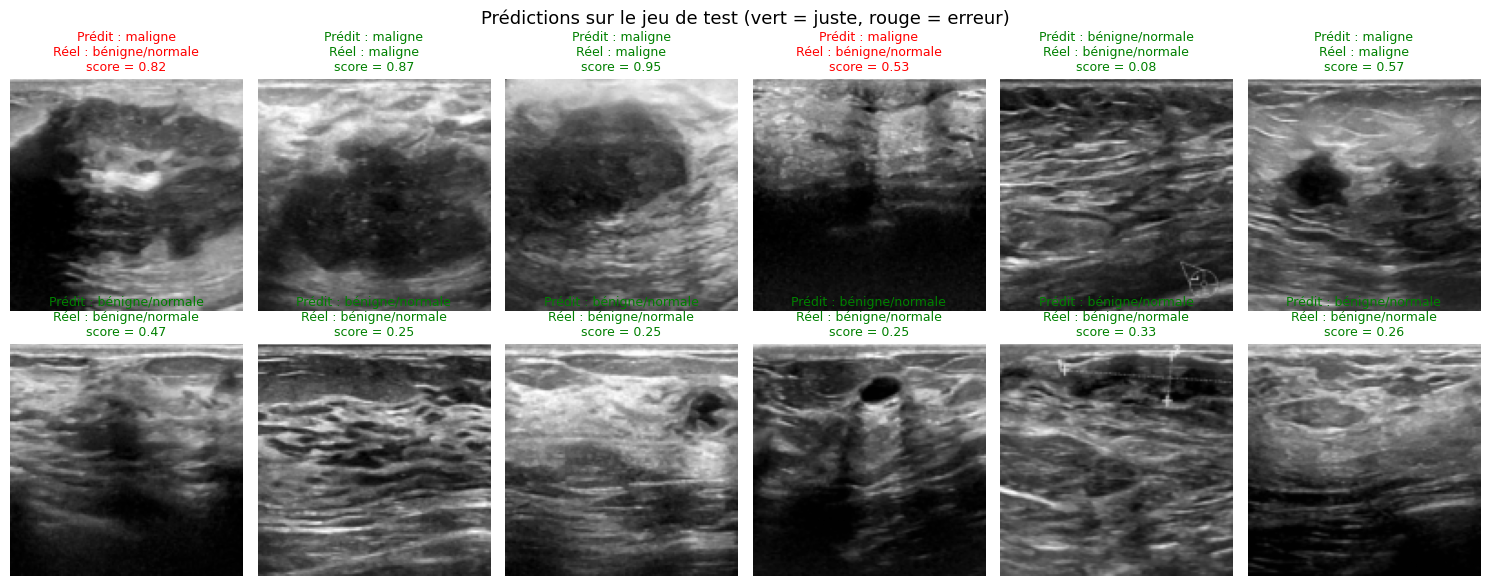

In [22]:
# Note pédagogique : afficher les images avec leur prédiction permet de repérer concrètement les erreurs du modèle.

test_scores = best_model.predict(X_test_best, verbose=0).reshape(-1)
rng = np.random.default_rng(SEED)
indices = rng.choice(len(X_test), size=12, replace=False)

fig, axes = plt.subplots(2, 6, figsize=(15, 6))
for ax, idx in zip(axes.flat, indices):
    pred = int(test_scores[idx] >= chosen_threshold)
    true = y_test[idx]
    ax.imshow(X_test[idx, ..., 0], cmap="gray")
    color = "green" if pred == true else "red"
    ax.set_title(f"Prédit : {CLASS_NAMES[pred]}\nRéel : {CLASS_NAMES[true]}\nscore = {test_scores[idx]:.2f}",
                 color=color, size=9)
    ax.axis("off")
fig.suptitle("Prédictions sur le jeu de test (vert = juste, rouge = erreur)", size=13)
plt.tight_layout()
plt.show()

## Partie 11 : Éthique et limites

Un bon score sur un jeu de test ne suffit pas pour utiliser un modèle auprès de vraies patientes. Quelques questions essentielles :

- **Représentativité des données** : BUSI a été collecté dans un seul hôpital (au Caire, en Égypte), avec un nombre limité d'appareils. Le modèle fonctionnerait-il aussi bien sur des échographies prises au Togo, avec d'autres appareils et d'autres réglages ?
- **Taille de l'échantillon** : 780 images, c'est très peu. Les résultats sont fragiles : quelques images de test en plus ou en moins changent nettement les pourcentages.
- **Résolution** : nous travaillons sur des images réduites à 128 × 128 pixels, alors que le radiologue voit l'image complète, en mouvement, avec le dossier de la patiente.
- **Biais** : qui est représenté dans les données ? Quels âges, quelles densités mammaires ? Un modèle peut être performant en moyenne et beaucoup moins pour certains groupes.
- **Responsabilité** : un tel outil doit rester une **aide à la décision**. La décision finale revient au professionnel de santé, et la patiente doit être informée.
- **Validation clinique** : avant tout usage réel, un modèle doit être validé sur des données externes, dans des conditions cliniques, et respecter la réglementation sur les dispositifs médicaux.

## Partie 12 : Enregistrer le modèle

Un modèle entraîné peut être enregistré dans un fichier, puis rechargé ailleurs : dans une application, ou derrière une **API REST**, comme nous le ferons dans la partie déploiement du cours.

In [23]:
# Note pédagogique : on enregistre le meilleur modèle au format Keras, puis on le recharge pour vérifier qu'il fonctionne.

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)
model_path = MODEL_DIR / f"breast_cancer_{best_name.lower().replace(' ', '_')}.keras"
best_model.save(model_path)
print(f"Modèle enregistré : {model_path} ({model_path.stat().st_size / 1e6:.1f} Mo)")
print(f"Seuil de décision à utiliser avec ce modèle : {chosen_threshold:.2f}")

# Recharger le modèle et prédire une image
reloaded = tf.keras.models.load_model(model_path)
image = X_test_best[:1]
score = float(reloaded.predict(image, verbose=0)[0, 0])
print(f"Score de malignité de la première image de test : {score:.2f} "
      f"→ {CLASS_NAMES[int(score >= chosen_threshold)]} (réel : {CLASS_NAMES[y_test[0]]})")

Modèle enregistré : models/breast_cancer_mobilenetv3.keras (4.8 Mo)
Seuil de décision à utiliser avec ce modèle : 0.51


Score de malignité de la première image de test : 0.70 → maligne (réel : maligne)


## 🧪 Pour aller plus loin (exercices facultatifs)

1. **Fine-tuning** : dégelez les dernières couches de MobileNetV3 (`base_model.trainable = True`), puis réentraînez avec un taux d'apprentissage 10 fois plus petit (`learning_rate=1e-4`). Le ROC-AUC s'améliore-t-il ?
2. **Autres architectures** : remplacez MobileNetV3 par `EfficientNetV2B0`, `ResNet50V2` ou `VGG16` (dans `tf.keras.applications`). Comparez les performances et la durée d'entraînement.
3. **Sans pondération des classes** : réentraînez le CNN sans `class_weight`. Que deviennent la sensibilité et l'accuracy ?
4. **Ensemble** : faites la moyenne des scores des deux modèles. Le ROC-AUC de cette combinaison est-il meilleur que celui de chaque modèle ?
5. **Autre jeu de données** : le notebook Kaggle d'origine utilise [BreakHis](https://www.kaggle.com/datasets/ambarish/breakhis), 7 909 images de biopsies au microscope. Il pèse 4,3 Go et nécessite un compte Kaggle : essayez d'y appliquer la même démarche sur un GPU Colab.

## 🎉 Ce que vous avez appris

- Les **CNN** utilisent des filtres de convolution partagés et du pooling pour exploiter la structure spatiale des images, avec beaucoup moins de paramètres qu'un réseau dense.
- Avec des **classes déséquilibrées**, l'accuracy trompe : on utilise le **ROC-AUC**, la **sensibilité**, la **spécificité** et la **matrice de confusion**.
- L'**augmentation de données** et la **pondération des classes** aident quand les données sont rares et déséquilibrées.
- Le **transfert d'apprentissage** permet d'obtenir de bons résultats avec peu de données, en réutilisant un modèle pré-entraîné.
- Le **seuil de décision** se choisit selon le contexte (et sur la validation) : en médecine, manquer un cancer coûte plus cher qu'une fausse alarme.
- Un modèle médical exige une réflexion sur les **biais**, la **validation clinique** et la **responsabilité humaine**.

👉 **Prochain lab** : `05_yolo_image_detection_example.ipynb`, où nous utiliserons un CNN pré-entraîné pour **détecter et localiser** plusieurs objets dans une image.